# 05. Expert supervision and fuzzy control

Original study laboratory. All generated data are synthetic.

Crisp supervisory rules produce traceable diagnoses. Fuzzy inference
instead represents graded membership. Mamdani uses min firing, max aggregation
and centroid defuzzification; Sugeno uses a normalized weighted average of
singleton consequents. The nine rules here form a PD-like surface used in an
incremental PI law. A separate example schedules PID gains. None of these
finite scenarios establishes global closed-loop stability.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 05 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-05.png)

The triangles show overlapping negative, zero and positive membership sets. Rule firing combines error and error-change memberships before producing an incremental action. The two inference methods differ in aggregation and defuzzification. Compare the recorded tracking and actuator curves; membership values are not calibrated probabilities or stability guarantees.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-05.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(5, ROOT / "laboratories/05-expert-fuzzy-control/results")
print(json.dumps(result["summary"], indent=2))

{
  "controllers": {
    "PI": {
      "iae": 2.8622955662746614,
      "ise": 0.3630729165011101,
      "itae": 103.07106908774517,
      "control_energy": 24.714924617917937,
      "total_variation": 1.5981973872837782,
      "constraint_violation": 0.0,
      "final_error": -0.003721239895360884
    },
    "Mamdani fuzzy PI": {
      "iae": 3.693665395042502,
      "ise": 0.5148406653707887,
      "itae": 129.61003741708646,
      "control_energy": 25.948940580848028,
      "total_variation": 2.443401367724391,
      "constraint_violation": 0.0,
      "final_error": -0.015348775097354106
    },
    "Sugeno fuzzy PI": {
      "iae": 3.832038381810863,
      "ise": 0.5235975959181622,
      "itae": 137.44645710044267,
      "control_energy": 26.098919535656208,
      "total_variation": 2.303610133168311,
      "constraint_violation": 0.0,
      "final_error": -0.01963093879612554
    },
    "fuzzy gain PID": {
      "iae": 3.4455162305114837,
      "ise": 0.3925889553639099,
      "it

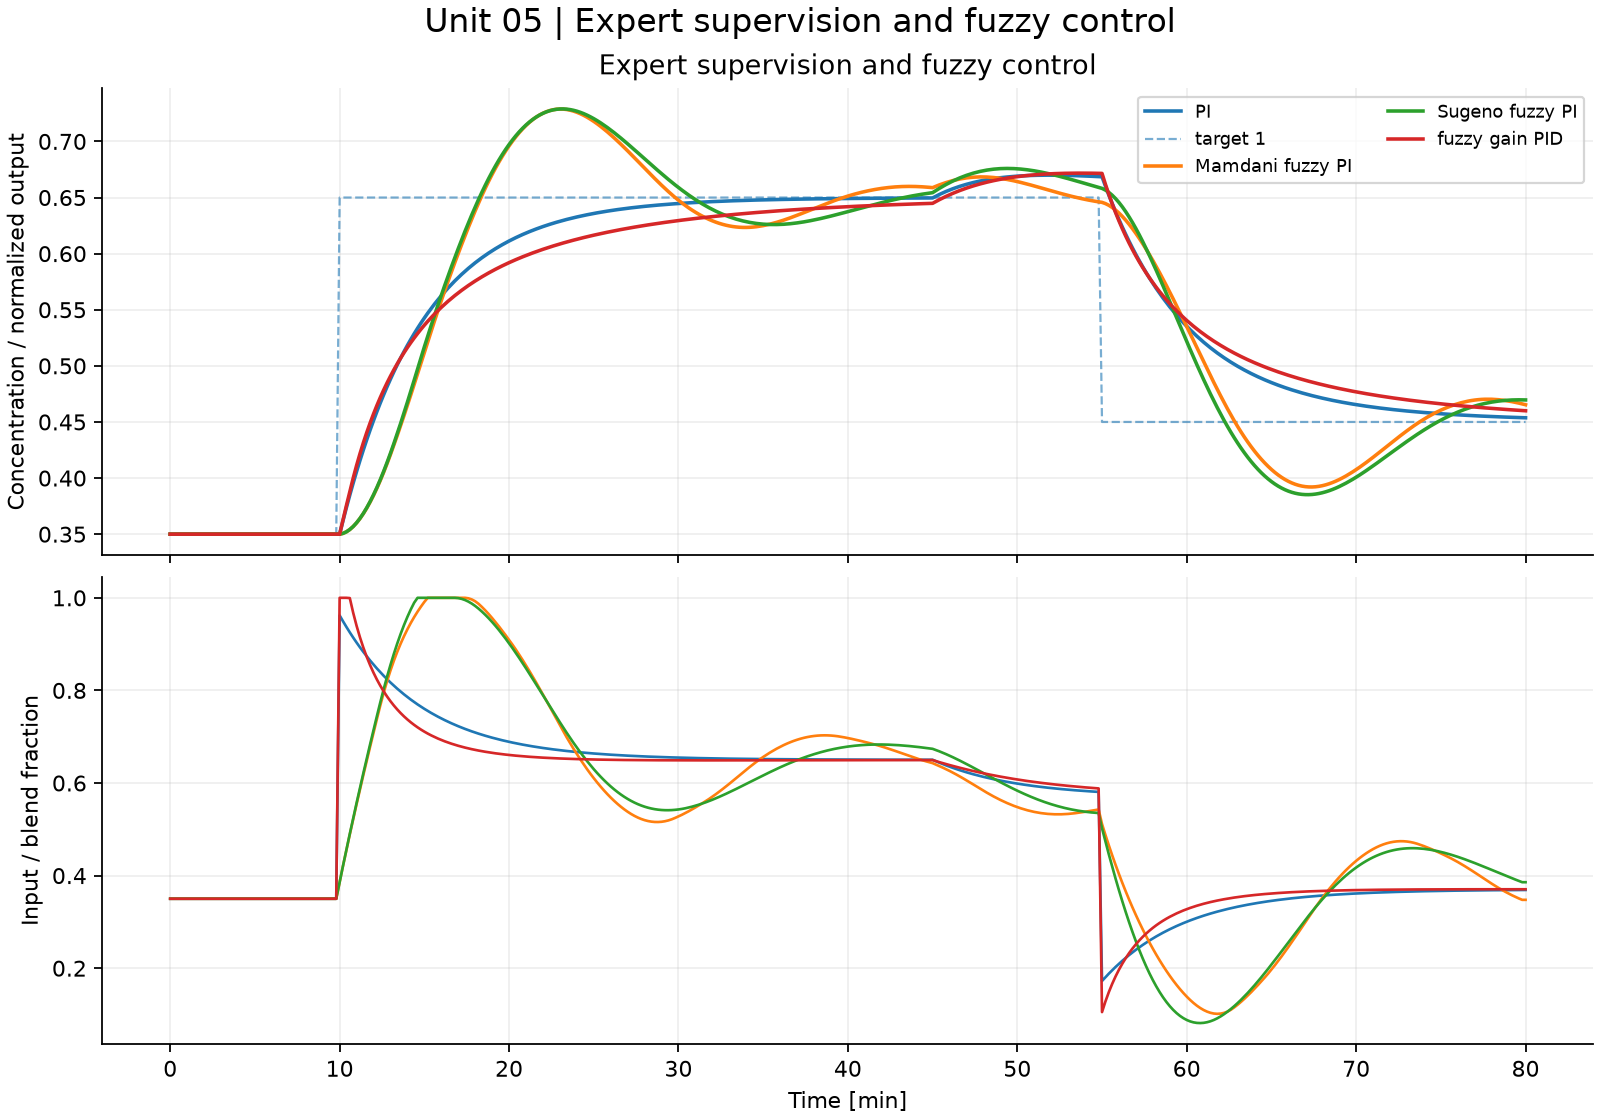

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/05-expert-fuzzy-control/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Original article names and detailed TikZ atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md) · [Download the vector atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/figures/tikz/benchmark-atlas.pdf)

![Tennessee Eastman process control problem — article section 3.13](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/tikz/13-tennessee-eastman.png)

The atlas identifies every benchmark by its original paper name and repository alias, with equipment, states and signals. The Tennessee Eastman companion plate maps the 12 commands and 41 measurements.

[Worked benchmark study for Unit 05](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-05.md)

![Unit 05 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-05.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.